In [1]:
# Project root — edit for your environment.
# Paths come from config.sh at the repo root (override via the environment).
import os, subprocess, sys


def _cfg(name):
    val = os.environ.get(name)
    if val:
        return val
    root = os.path.abspath(os.getcwd())          # notebooks have no __file__
    while not os.path.isfile(os.path.join(root, "config.sh")) \
            and root != os.path.dirname(root):
        root = os.path.dirname(root)
    val = subprocess.check_output(
        ["bash", "-c", f'source "$1" 2>/dev/null; printf "%s" "${{{name}}}"',
         "_", os.path.join(root, "config.sh")], text=True)
    if not val:
        raise SystemExit(f"ERROR: {name} is not set in the environment or in config.sh")
    return val


PROJ_ROOT = _cfg("PROJ_ROOT")

# Cache for the expensive per-region feature counts (see the "CACHED" cell below).
# Written next to this notebook. Delete it to force a full recompute.
SEGDUP_COUNTS_TSV = "merged_segdup_with_feature_counts.tsv"


In [2]:
import os
import gc

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
# import pybedtools
import intervaltree  # Or use GenomeIntervalTree from intervaltree-bio
from tqdm import tqdm
from kneed import KneeLocator
from collections import defaultdict


In [3]:
chr_colors = {
    'chr1': '#FF6B6B', 'chr2': '#4ECDC4', 'chr3': '#45B7D1', 'chr4': '#FFA07A',
    'chr5': '#92D050', 'chr6': '#D35FB7', 'chr7': '#FFC000', 'chr8': '#00B0F0',
    'chr9': '#A2D96C', 'chr10': '#C00000', 'chr11': '#7030A0', 'chr12': '#FF5733',
    'chr13': '#00AEEF', 'chr14': '#FF99CC', 'chr15': '#8FD8D8', 'chr16': '#F6546A',
    'chr17': '#468499', 'chr18': '#FFD700', 'chr19': '#088DA5', 'chr20': '#F08080',
    'chr21': '#6A5ACD', 'chr22': '#65B891', 'chr23': '#FFA500', 'chr24': '#BA55D3',
    'chr25': '#9370DB', 'chr26': '#3CB371', 'chr27': '#7B68EE', 'chr28': '#40E0D0',
    'chrX': '#FF1493',  # Distinct pink for X
    'chrY': '#14FF82'   # Dark blue for Y
}

In [4]:
dup = pd.read_csv(
    f"{PROJ_ROOT}/code/command-line-script/genome-annotation/biser/hifiasm-041425/segdup_output_duplicateLinkRemoved.bedpe",
    sep="\t",
    header=None,
    names=["chr1", "start1", "end1", "chr2", "start2", "end2","reference","score","strand1","strand2","max_len","aln_len","cigar","optional"]
)
print(dup.shape)
# Assuming 'dup' is your DataFrame
dup = pd.concat([
    dup[['chr1', 'start1', 'end1']].rename(columns={'chr1': 'chrom', 'start1': 'start', 'end1': 'end'}),
    dup[['chr2', 'start2', 'end2']].rename(columns={'chr2': 'chrom', 'start2': 'start', 'end2': 'end'})
], ignore_index=True)

(203532, 14)


In [5]:
## Total number of basepairs 
def merge_segdup_intervals(df):
    """
    Merge overlapping or adjacent segdup hotspot intervals
    """
    merged_data = []
    
    # Group by chromosome
    for chrom, group in df.groupby('chrom'):
        # Sort by start position
        sorted_group = group.sort_values('start')
        
        if len(sorted_group) == 0:
            continue
            
        merged_intervals = []
        current_start = sorted_group.iloc[0]['start']
        current_end = sorted_group.iloc[0]['end']
        
        for i in range(1, len(sorted_group)):
            row = sorted_group.iloc[i]
            start, end = row['start'], row['end']
            
            # Check for overlap or adjacency
            if start <= current_end:
                # Overlapping or adjacent - extend current interval if needed
                current_end = max(current_end, end)
            else:
                # No overlap - save current interval and start new one
                merged_intervals.append({
                    'chrom': chrom,
                    'start': current_start,
                    'end': current_end,
                    'Length': current_end - current_start
                })
                current_start = start
                current_end = end
        
        # Don't forget the last interval
        merged_intervals.append({
            'chrom': chrom,
            'start': current_start,
            'end': current_end,
            'Length': current_end - current_start
        })
        
        merged_data.extend(merged_intervals)
    
    return pd.DataFrame(merged_data)

In [6]:
# hotspot_df = dup
# Merge the hotspot intervals
merged_segdup = merge_segdup_intervals(dup)
print(merged_segdup.shape)

(29101, 4)


In [7]:
merged_segdup["Length"].sum()

np.int64(528097744)

In [8]:
# Load genes with overlap information 
## This is calculated from calculate_segdup_geneOverlap_newHiFiAnnotation.ipynb
genes = pd.read_csv(_cfg("SEGDUP_GENE_OVERLAP_TSV"), sep="\t")
genes["Start"] = genes["Start"].astype(int)
genes["End"] = genes["End"].astype(int)
genes["overlaps_dup"] = genes["overlaps_dup"].astype(bool)
genes

,Unnamed: 0,Chromosome,source,type,Gene Start,Gene End,score,Strand,phase,attributes,gene,Start,End,overlaps_dup
0,0,chrX,Liftoff,gene,25545,30066,.,-,.,ID=gene-LOC111814891;Dbxref=GeneID:111814891;N...,LOC111814891,25544,30066,True
1,7,chrX,Liftoff,gene,95261,134513,.,-,.,ID=gene-Vamp7;Dbxref=GeneID:101571755;Name=Vam...,VAMP7,95260,134513,False
2,21,chrX,Liftoff,gene,184599,192686,.,-,.,ID=gene-Spry3;Dbxref=GeneID:101570555;Name=Spr...,SPRY3,184598,192686,False
3,29,chrX,Liftoff,gene,247132,249699,.,-,.,ID=gene-LOC101572155;Dbxref=GeneID:101572155;N...,LOC101572155,247131,249699,True
4,39,chrX,Liftoff,gene,359139,515200,.,+,.,ID=gene-Tmlhe;Dbxref=GeneID:101571355;Name=Tml...,TMLHE,359138,515200,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26268,1205356,seq31,AUGUSTUS,gene,697591,698610,.,-,.,ID=gene-Rad51-dl2;Name=Rad51-dl2;origin=de_novo,RAD51-DL2,697590,698610,True
26269,1205363,seq200,Liftoff,gene,1549,1631,.,-,.,ID=gene-Trnal-cag-4;Dbxref=GeneID:111814974;Na...,TRNAL-CAG-4,1548,1631,True
26270,1205366,seq200,Liftoff,gene,2251,2322,.,+,.,ID=gene-Trnad-guc-9;Dbxref=GeneID:111814972;Na...,TRNAD-GUC-9,2250,2322,True
26271,1205369,seq200,Liftoff,gene,2727,2798,.,+,.,ID=gene-Trnag-ucc-7;Dbxref=GeneID:111814973;Na...,TRNAG-UCC-7,2726,2798,True


In [9]:
## Filter segdup to assembled chromosomes
merged_segdup = merged_segdup[merged_segdup["chrom"].str.contains("chr")]

# reset_index is REQUIRED: build_segdup_tree stores the DataFrame index as the
# interval payload and count_overlaps_* writes into a positional list, so a
# non-contiguous index would silently drop counts for regions past the end.
merged_segdup = merged_segdup.reset_index(drop=True)
print(f"{len(merged_segdup):,} merged segdup regions on assembled chromosomes")


28,961 merged segdup regions on assembled chromosomes


In [17]:
# =============================================================================
# Per-region feature counts  --  CACHED  (this is the ~15 min step)
#
# Loads the 1.3 GB RepeatMasker GFF3 (~4 GB in RAM), assigns each of the 8.78 M
# repeats to a mutually exclusive class, and counts how many genes / repeats of
# each class overlap every merged segdup region.
#
# The result is cached to SEGDUP_COUNTS_TSV. On later runs the counts are read
# straight back and this whole pipeline is skipped. The cache is keyed on the
# merged region set itself (chrom/start/end), so if the upstream segdup bedpe
# changes the cache is detected as stale and rebuilt automatically.
#
# Set FORCE_RECOMPUTE = True (or delete the cache file) to force a rebuild.
# =============================================================================
FORCE_RECOMPUTE = False

KEY_COLS = ["chrom", "start", "end"]
COUNT_COLS = [
    "gene_count",
    "repeat_count",
    "unknown_repeat_count",
    "LINE_repeat_count",
    "LTR_repeat_count",
    "SINE_repeat_count",
    "DNA_transposon_repeat_count",
]
# (class label in repeat_category, destination column)
REPEAT_CLASSES = [
    ("Unknown", "unknown_repeat_count"),
    ("LINE", "LINE_repeat_count"),
    ("LTR", "LTR_repeat_count"),
    ("SINE", "SINE_repeat_count"),
    ("DNA_transposon", "DNA_transposon_repeat_count"),
]


def build_segdup_tree(segdup_df, chrom_col="chrom", start_col="start", end_col="end"):
    """Interval tree per chromosome over the merged segdup regions."""
    trees = defaultdict(intervaltree.IntervalTree)
    for idx, row in segdup_df.iterrows():
        trees[row[chrom_col]].addi(row[start_col], row[end_col], data=idx)
    return trees


def count_overlaps_optimized_with_progress(
    segdup_trees,
    target_df,
    segdup_total_count,
    target_chrom_col="Chromosome",
    target_start_col="Start",
    target_end_col="End",
    desc=None,
):
    """For each segdup region, how many intervals of target_df overlap it."""
    counts = [0] * segdup_total_count
    for _, target_row in tqdm(
        target_df.iterrows(),
        total=len(target_df),
        desc=desc or f"Processing {len(target_df):,} intervals",
    ):
        tree = segdup_trees.get(target_row[target_chrom_col])
        if tree is None:
            continue
        for iv in tree.overlap(target_row[target_start_col], target_row[target_end_col]):
            if iv.data < segdup_total_count:
                counts[iv.data] += 1
    return counts


def categorize_repeats_exclusive(df):
    """
    Assign one mutually exclusive repeat class per row, in priority order
    (DNA transposon > SINE > LINE > LTR > Unknown), writing IN PLACE.

    In place on purpose: `repeats` is ~4 GB, so the previous `.copy()` doubled
    peak memory for no benefit.
    """
    attrs = df["attributes"]
    df["repeat_category"] = "Other"

    def unclaimed(pattern):
        return attrs.str.contains(pattern, na=False, regex=True) & (
            df["repeat_category"] == "Other"
        )

    df.loc[unclaimed(r"DNA|hobo-Activator|Tc1-IS630-Pogo|En-Spm|MULE-MuDR|"
                     r"PiggyBac|Tourist/Harbinger|P-element|Transib|Mirage"),
           "repeat_category"] = "DNA_transposon"
    df.loc[unclaimed(r"SINE|Alu"), "repeat_category"] = "SINE"
    df.loc[unclaimed(r"LINE|L1|L2|CR1|Rex|RTE|CIN4"), "repeat_category"] = "LINE"
    df.loc[unclaimed(r"LTR|ltr-|Retroviral|Ty1/Copia|Gypsy/DIRS1|BEL/Pao"),
           "repeat_category"] = "LTR"
    df.loc[unclaimed(r"Unknown|Unclassified|rnd-"), "repeat_category"] = "Unknown"
    return df


def _load_cached_counts(path, regions):
    """regions + count columns from cache, or None if absent/stale."""
    if FORCE_RECOMPUTE:
        print("FORCE_RECOMPUTE is set -> recomputing")
        return None
    if not os.path.exists(path):
        print(f"no cache at {path} -> computing from scratch")
        return None
    cached = pd.read_csv(path, sep="\t")
    if not set(KEY_COLS + COUNT_COLS).issubset(cached.columns):
        print("cache is missing expected columns -> recomputing")
        return None
    # Compare by value, not by dtype: read_csv may hand back int32/float where
    # the freshly merged frame holds int64, and DataFrame.equals is dtype-strict,
    # which would silently force a full 15 min recompute on every run.
    def _key(df):
        return list(zip(df["chrom"].astype(str),
                        df["start"].astype("int64"),
                        df["end"].astype("int64")))

    if _key(regions) != _key(cached):
        print("cache does not match the current segdup regions -> recomputing")
        return None
    return regions.merge(cached[KEY_COLS + COUNT_COLS], on=KEY_COLS, how="left")


_cached = _load_cached_counts(SEGDUP_COUNTS_TSV, merged_segdup)

if _cached is not None:
    merged_segdup = _cached
    print(f"Loaded feature counts from cache: {SEGDUP_COUNTS_TSV}")
    print(f"  {len(merged_segdup):,} regions -- skipped ~15 min of recomputation")
else:
    segdup_trees = build_segdup_tree(merged_segdup)

    repeats = pd.read_csv(
        f"{PROJ_ROOT}/output/outputs-from-repeatmasker/hifiasm-041425-haphic/"
        "assembly_final.sorted.headerRenamed.fasta.gff3",
        sep="\t",
        skiprows=1,
        header=None,
        names=["seqid", "source", "type", "Start", "End", "score",
               "strand", "phase", "attributes"],
    )

    seq_to_chr = {
        "seq1": "chrX",  "seq23": "chrY", "seq2": "chr1",  "seq3": "chr2",
        "seq4": "chr3",  "seq5": "chr4",  "seq6": "chr5",  "seq7": "chr6",
        "seq8": "chr7",  "seq9": "chr8",  "seq10": "chr9", "seq11": "chr10",
        "seq12": "chr11", "seq13": "chr12", "seq14": "chr13", "seq15": "chr14",
        "seq16": "chr15", "seq17": "chr16", "seq18": "chr17", "seq19": "chr18",
        "seq20": "chr19", "seq21": "chr20", "seq22": "chr21", "seq24": "chr22",
        "seq25": "chr23", "seq26": "chr24", "seq27": "chr25", "seq28": "chr26",
        "seq29": "chr27", "seq30": "chr28",
    }
    repeats["Chromosome"] = repeats["seqid"].replace(seq_to_chr)
    print(f"{len(repeats):,} RepeatMasker features loaded")

    repeats = categorize_repeats_exclusive(repeats)

    print("\nEXCLUSIVE REPEAT CATEGORY SUMMARY")
    print("=" * 70)
    for cat in ["Unknown", "LTR", "SINE", "LINE", "DNA_transposon", "Other"]:
        m = repeats["repeat_category"] == cat
        n = int(m.sum())
        bp = int((repeats.loc[m, "End"] - repeats.loc[m, "Start"]).sum())
        print(f"{cat:<15} {n:>9,} repeats | {bp:>13,} bp | "
              f"{bp / 1e6:>8.1f} Mbp | {n / len(repeats) * 100:>5.1f}%")
    print("-" * 70)

    print("\nCounting gene overlaps...")
    merged_segdup["gene_count"] = count_overlaps_optimized_with_progress(
        segdup_trees, genes, len(merged_segdup), desc="genes")

    print("Counting all-repeat overlaps...")
    merged_segdup["repeat_count"] = count_overlaps_optimized_with_progress(
        segdup_trees, repeats, len(merged_segdup), desc="all repeats")

    for cat, col in REPEAT_CLASSES:
        print(f"Counting {cat} repeat overlaps...")
        sub = repeats[repeats["repeat_category"] == cat]
        merged_segdup[col] = count_overlaps_optimized_with_progress(
            segdup_trees, sub, len(merged_segdup), desc=f"{cat} repeats")
        del sub
        gc.collect()

    # `repeats` is ~4 GB and is not needed downstream -- release it.
    del repeats
    gc.collect()

    merged_segdup.to_csv(SEGDUP_COUNTS_TSV, sep="\t", index=False)
    print(f"\nCached feature counts -> {SEGDUP_COUNTS_TSV}")

merged_segdup[KEY_COLS + ["Length"] + COUNT_COLS].head()


no cache at merged_segdup_with_feature_counts.tsv -> computing from scratch
8,780,221 RepeatMasker features loaded

EXCLUSIVE REPEAT CATEGORY SUMMARY
Unknown         2,459,376 repeats |   637,244,502 bp |    637.2 Mbp |  28.0%
LTR             1,128,648 repeats |   179,956,080 bp |    180.0 Mbp |  12.9%
SINE            2,573,341 repeats |   344,814,763 bp |    344.8 Mbp |  29.3%
LINE            1,438,704 repeats |   703,934,185 bp |    703.9 Mbp |  16.4%
DNA_transposon     80,045 repeats |    17,153,165 bp |     17.2 Mbp |   0.9%
Other           1,100,107 repeats |    53,377,917 bp |     53.4 Mbp |  12.5%
----------------------------------------------------------------------

Counting gene overlaps...


genes: 100%|██████████| 26273/26273 [00:01<00:00, 22350.22it/s]


Counting all-repeat overlaps...


all repeats: 100%|██████████| 8780221/8780221 [05:56<00:00, 24616.90it/s]


Counting Unknown repeat overlaps...


...

SINE repeats: 100%|██████████| 2573341/2573341 [01:44<00:00, 24651.97it/s]


Counting DNA_transposon repeat overlaps...


DNA_transposon repeats: 100%|██████████| 80045/80045 [00:03<00:00, 24592.40it/s]



Cached feature counts -> merged_segdup_with_feature_counts.tsv


,chrom,start,end,Length,gene_count,repeat_count,unknown_repeat_count,LINE_repeat_count,LTR_repeat_count,SINE_repeat_count,DNA_transposon_repeat_count
0,chr1,11921,153124,141203,2,593,142,93,160,131,1
1,chr1,245634,248417,2783,1,22,3,4,5,10,0
2,chr1,294326,297142,2816,1,4,0,0,2,0,0
3,chr1,476403,483932,7529,0,6,1,1,1,1,0
4,chr1,488435,488779,344,0,0,0,0,0,0,0


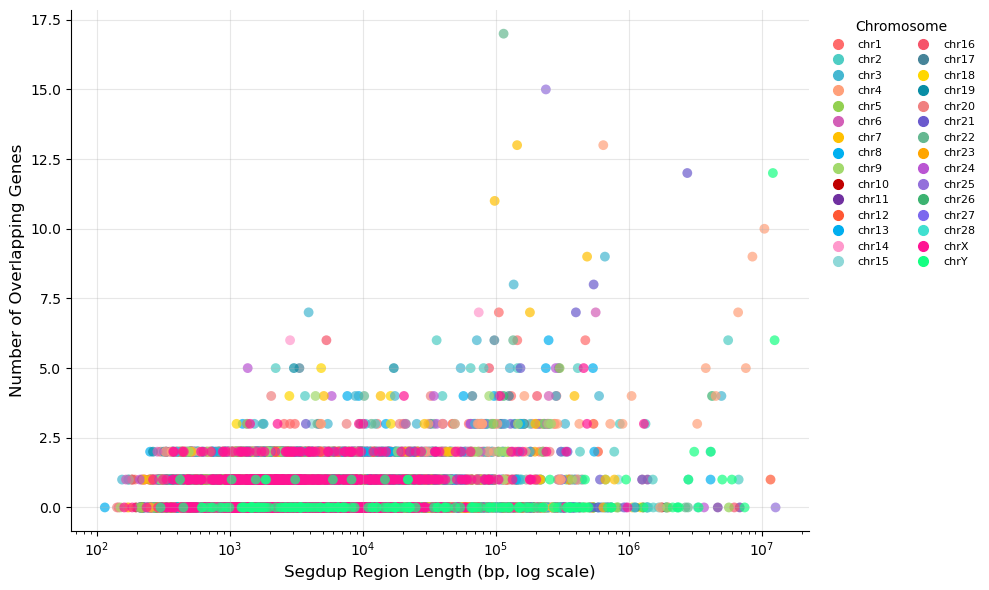

Correlation between length and gene count: 0.152

Statistics:
Average length: 18,037 bp
Average gene count: 0.50
Largest region: 12,756,190 bp with 0 genes
Region with most genes: 17 genes with length 114,828 bp


In [18]:
# Scatter of gene count vs segdup region length, coloured by chromosome.
#
# This used to call plt.scatter() once per row inside
#     for i, row in merged_segdup.iterrows():
# i.e. 28,961 separate scatter calls, each building its own PathCollection
# artist. That is why the cell appeared to hang -- it was not the data size.
# One vectorised call draws the identical figure in well under a second.

point_colors = merged_segdup["chrom"].map(chr_colors).fillna("#CCCCCC")

plt.figure(figsize=(10, 6))
plt.scatter(merged_segdup["Length"], merged_segdup["gene_count"],
            c=point_colors, alpha=0.7, s=50, edgecolors="none")

plt.xlabel("Segdup Region Length (bp)", fontsize=12)
plt.ylabel("Number of Overlapping Genes", fontsize=12)
plt.grid(True, alpha=0.3)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

if merged_segdup["Length"].max() / merged_segdup["Length"].min() > 100:
    plt.xscale("log")
    plt.xlabel("Segdup Region Length (bp, log scale)", fontsize=12)

# One legend entry per chromosome actually present. The old
# `label=chrom if i == 0 else ""` only ever labelled a single point, so the
# legend was meaningless (and never drawn).
present = [c for c in chr_colors if (merged_segdup["chrom"] == c).any()]
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=7,
                      color=chr_colors[c], label=c) for c in present]
ax.legend(handles=handles, ncol=2, fontsize=8, frameon=False,
          loc="upper left", bbox_to_anchor=(1.01, 1.0), title="Chromosome")

plt.tight_layout()
plt.show()

correlation = merged_segdup["Length"].corr(merged_segdup["gene_count"])
print(f"Correlation between length and gene count: {correlation:.3f}")
print("\nStatistics:")
print(f"Average length: {merged_segdup['Length'].mean():,.0f} bp")
print(f"Average gene count: {merged_segdup['gene_count'].mean():.2f}")
print(f"Largest region: {merged_segdup['Length'].max():,} bp with "
      f"{merged_segdup.loc[merged_segdup['Length'].idxmax(), 'gene_count']} genes")
print(f"Region with most genes: {merged_segdup['gene_count'].max()} genes with length "
      f"{merged_segdup.loc[merged_segdup['gene_count'].idxmax(), 'Length']:,} bp")


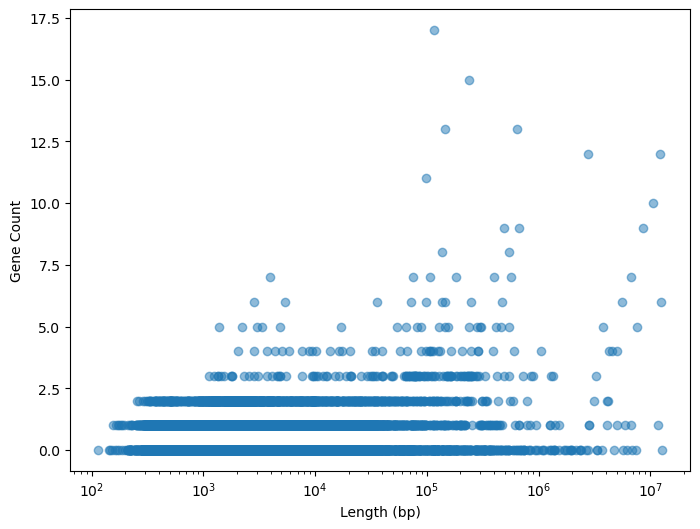

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(merged_segdup['Length'], merged_segdup['gene_count'], alpha=0.5)
plt.xlabel('Length (bp)')
plt.ylabel('Gene Count')
plt.xscale("log")
plt.show()

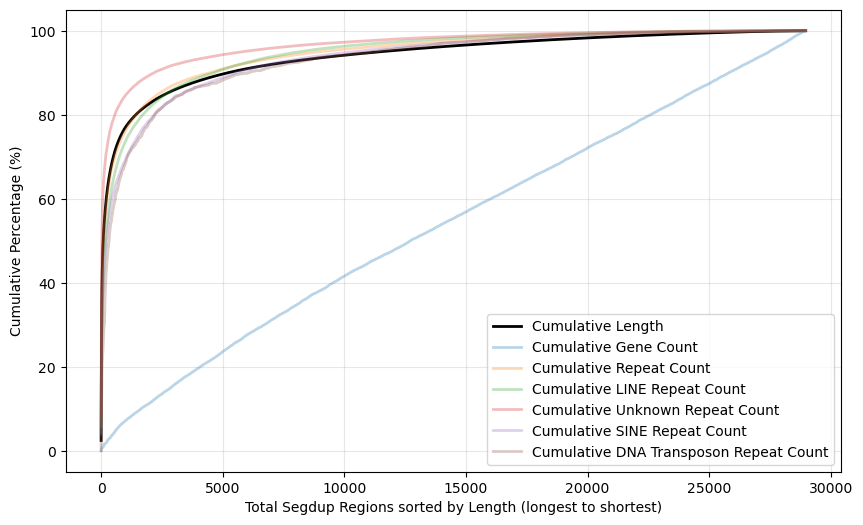

In [20]:
# Sort by Length for cumulative length
sorted_by_length = merged_segdup.sort_values('Length', ascending=False)
sorted_by_length['Cumulative_Length'] = sorted_by_length['Length'].cumsum()
total_length = sorted_by_length['Length'].sum()
sorted_by_length['Cumulative_Length_Pct'] = (sorted_by_length['Cumulative_Length'] / total_length) * 100

# Use the same sorted order for gene count calculations
sorted_by_length['Cumulative_Genes'] = sorted_by_length['gene_count'].cumsum()
total_genes = sorted_by_length['gene_count'].sum()
sorted_by_length['Cumulative_Genes_Pct'] = (sorted_by_length['Cumulative_Genes'] / total_genes) * 100

# Use the same sorted order for repeat count calculations
sorted_by_length['Cumulative_Repeats'] = sorted_by_length['repeat_count'].cumsum()
total_repeats = sorted_by_length['repeat_count'].sum()
sorted_by_length['Cumulative_Repeat_Pct'] = (sorted_by_length['Cumulative_Repeats'] / total_repeats) * 100

# Use the same sorted order for repeat count calculations
sorted_by_length['Cumulative_LINE'] = sorted_by_length['LINE_repeat_count'].cumsum()
total_repeats = sorted_by_length['LINE_repeat_count'].sum()
sorted_by_length['Cumulative_LINE_Pct'] = (sorted_by_length['Cumulative_LINE'] / total_repeats) * 100
# Use the same sorted order for repeat count calculations
sorted_by_length['Cumulative_Unknown'] = sorted_by_length['unknown_repeat_count'].cumsum()
total_repeats = sorted_by_length['unknown_repeat_count'].sum()
sorted_by_length['Cumulative_Unknown_Pct'] = (sorted_by_length['Cumulative_Unknown'] / total_repeats) * 100
# Use the same sorted order for repeat count calculations
sorted_by_length['Cumulative_SINE'] = sorted_by_length['SINE_repeat_count'].cumsum()
total_repeats = sorted_by_length['SINE_repeat_count'].sum()
sorted_by_length['Cumulative_SINE_Pct'] = (sorted_by_length['Cumulative_SINE'] / total_repeats) * 100
# Use the same sorted order for repeat count calculations
sorted_by_length['Cumulative_DNA_transposon'] = sorted_by_length['DNA_transposon_repeat_count'].cumsum()
total_repeats = sorted_by_length['DNA_transposon_repeat_count'].sum()
sorted_by_length['Cumulative_DNA_transposon_Pct'] = (sorted_by_length['Cumulative_DNA_transposon'] / total_repeats) * 100

# Create the plot
plt.figure(figsize=(10, 6))

# Cumulative Length
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Cumulative_Length_Pct'], 
         label='Cumulative Length', linewidth=2, color="black")

# Cumulative Gene Count
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Cumulative_Genes_Pct'], 
         label='Cumulative Gene Count', linewidth=2,alpha=0.3)

# Cumulative Repeat Count
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Cumulative_Repeat_Pct'], 
         label='Cumulative Repeat Count', linewidth=2,alpha=0.3)

# Cumulative Repeat Count
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Cumulative_LINE_Pct'], 
         label='Cumulative LINE Repeat Count', linewidth=2,alpha=0.3)
# Cumulative Repeat Count
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Cumulative_Unknown_Pct'], 
         label='Cumulative Unknown Repeat Count', linewidth=2,alpha=0.3)
# Cumulative Repeat Count
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Cumulative_SINE_Pct'], 
         label='Cumulative SINE Repeat Count', linewidth=2,alpha=0.3)
# Cumulative Repeat Count
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Cumulative_DNA_transposon_Pct'], 
         label='Cumulative DNA Transposon Repeat Count', linewidth=2,alpha=0.3)

plt.xlabel('Total Segdup Regions sorted by Length (longest to shortest)')
plt.ylabel('Cumulative Percentage (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
# Defined BEFORE the plot cell that consumes it. This used to sit one cell
# AFTER the big plot cell, so a top-to-bottom run died with
# NameError: name 'curves' is not defined.
curves = {
    "Length": "Cumulative_Length_Pct",
    "Genes": "Cumulative_Genes_Pct",
    "All_Repeats": "Cumulative_Repeat_Pct",
    "LINE": "Cumulative_LINE_Pct",
    "Unknown": "Cumulative_Unknown_Pct",
    "SINE": "Cumulative_SINE_Pct",
    "DNA_transposon": "Cumulative_DNA_transposon_Pct",
}
curves


{'Length': 'Cumulative_Length_Pct',
 'Genes': 'Cumulative_Genes_Pct',
 'All_Repeats': 'Cumulative_Repeat_Pct',
 'LINE': 'Cumulative_LINE_Pct',
 'Unknown': 'Cumulative_Unknown_Pct',
 'SINE': 'Cumulative_SINE_Pct',
 'DNA_transposon': 'Cumulative_DNA_transposon_Pct'}

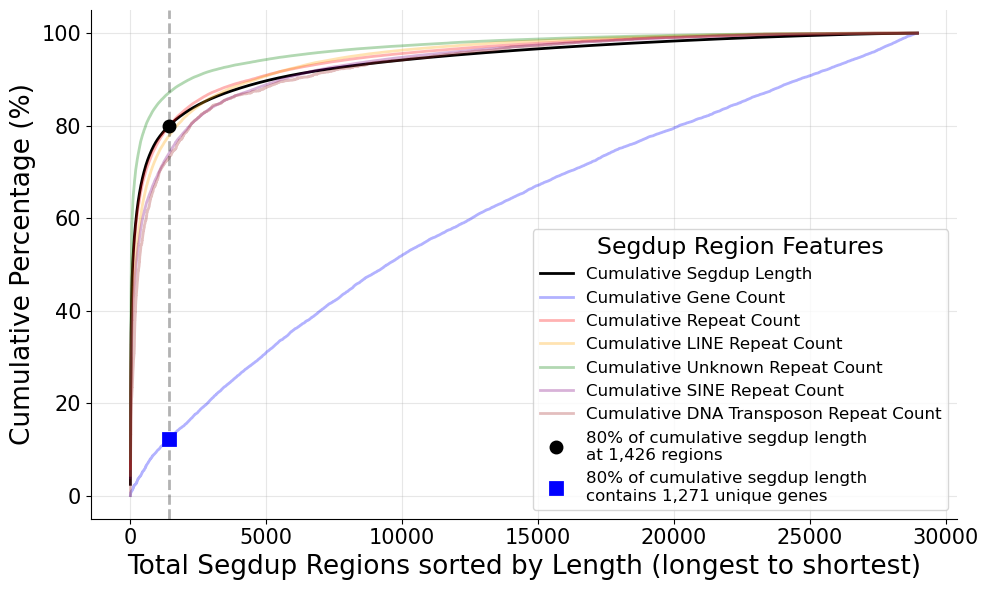

Length 80%: 1,426 regions | Genes at 80% length: 12.2% (1,273 unique genes)


In [22]:
# Paste this entire block into ONE new cell in 05_cumulative_feature_overlap.ipynb.
# SELF-CONTAINED: rebuilds sorted_by_length with ALL cumulative columns, plots
# every curve, draws the 80% cumulative-segdup-LENGTH vertical line (black), and
# adds a gene marker at that SAME x-position (where the length line crosses the
# gene curve), showing the cumulative-gene % and gene count in the legend.
#
# Requires `merged_segdup`, `genes`, `curves`, `np`, `plt`, and `intervaltree` already defined (they are).

# --- Rebuild all cumulative columns (safe to run anytime) ---
sorted_by_length = merged_segdup.sort_values('Length', ascending=False).copy()

sorted_by_length['Cumulative_Length'] = sorted_by_length['Length'].cumsum()
total_length = sorted_by_length['Length'].sum()
sorted_by_length['Cumulative_Length_Pct'] = (sorted_by_length['Cumulative_Length'] / total_length) * 100

# Cumulative UNIQUE gene count (each gene counted once, even if it spans
# multiple merged regions). Walk length-sorted regions accumulating the set of
# distinct genes covered -- a gene is added the first time any region covers it.
_gene_trees = {}
for _chrom, _grp in genes.groupby('Chromosome'):
    _t = intervaltree.IntervalTree()
    for _, _g in _grp.iterrows():
        _t.addi(int(_g['Start']), int(_g['End']), _g['gene'])
    _gene_trees[_chrom] = _t

_covered_genes = set()
_cum_unique = []
for _, _r in sorted_by_length.iterrows():
    _t = _gene_trees.get(_r['chrom'])
    if _t:
        for _iv in _t.overlap(int(_r['start']), int(_r['end'])):
            _covered_genes.add(_iv.data)
    _cum_unique.append(len(_covered_genes))

total_genes = len(_covered_genes)
sorted_by_length['Cumulative_Genes'] = _cum_unique
sorted_by_length['Cumulative_Genes_Pct'] = (np.array(_cum_unique) / total_genes) * 100

sorted_by_length['Cumulative_Repeats'] = sorted_by_length['repeat_count'].cumsum()
total_repeats = sorted_by_length['repeat_count'].sum()
sorted_by_length['Cumulative_Repeat_Pct'] = (sorted_by_length['Cumulative_Repeats'] / total_repeats) * 100

sorted_by_length['Cumulative_LINE'] = sorted_by_length['LINE_repeat_count'].cumsum()
total_repeats = sorted_by_length['LINE_repeat_count'].sum()
sorted_by_length['Cumulative_LINE_Pct'] = (sorted_by_length['Cumulative_LINE'] / total_repeats) * 100

sorted_by_length['Cumulative_Unknown'] = sorted_by_length['unknown_repeat_count'].cumsum()
total_repeats = sorted_by_length['unknown_repeat_count'].sum()
sorted_by_length['Cumulative_Unknown_Pct'] = (sorted_by_length['Cumulative_Unknown'] / total_repeats) * 100

sorted_by_length['Cumulative_SINE'] = sorted_by_length['SINE_repeat_count'].cumsum()
total_repeats = sorted_by_length['SINE_repeat_count'].sum()
sorted_by_length['Cumulative_SINE_Pct'] = (sorted_by_length['Cumulative_SINE'] / total_repeats) * 100

sorted_by_length['Cumulative_DNA_transposon'] = sorted_by_length['DNA_transposon_repeat_count'].cumsum()
total_repeats = sorted_by_length['DNA_transposon_repeat_count'].sum()
sorted_by_length['Cumulative_DNA_transposon_Pct'] = (sorted_by_length['Cumulative_DNA_transposon'] / total_repeats) * 100


# --- Plot with 80% threshold for Length + gene intersection ---
size=17
plt.figure(figsize=(10, 6))

colors = {
    'Length': 'black',
    'Genes': 'blue',
    'All_Repeats': 'red',
    'LINE': 'orange',
    'Unknown': 'green',
    'SINE': 'purple',
    'DNA_transposon': 'brown'
}

# Clear labels that make it explicit these are cumulative curves
label_map = {
    'Length': 'Cumulative Segdup Length',
    'Genes': 'Cumulative Gene Count',
    'All_Repeats': 'Cumulative Repeat Count',
    'LINE': 'Cumulative LINE Repeat Count',
    'Unknown': 'Cumulative Unknown Repeat Count',
    'SINE': 'Cumulative SINE Repeat Count',
    'DNA_transposon': 'Cumulative DNA Transposon Repeat Count',
}

for name, col in curves.items():
    plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length[col],
             label=label_map[name], linewidth=2,
             alpha=0.3 if name != 'Length' else 1.0,
             color=colors[name])

# --- 80% threshold for cumulative segdup LENGTH (black) ---
y_length = sorted_by_length['Cumulative_Length_Pct'].values
region_80_idx = int(np.argmax(y_length >= 80))
plt.axvline(x=region_80_idx + 1, color='black', linestyle='--', alpha=0.3, linewidth=2)
plt.plot(region_80_idx + 1, 80, 'o', color='black', markersize=8,
         markerfacecolor='black', markeredgecolor='black', markeredgewidth=2,
         label=f'80% of cumulative segdup length\nat {region_80_idx + 1:,} regions')

# --- Gene intersection AT the length-80% line (blue marker on the gene curve) ---
genes_pct_at_80 = float(sorted_by_length['Cumulative_Genes_Pct'].iloc[region_80_idx])
n_genes_at_80 = int(sorted_by_length['Cumulative_Genes'].iloc[region_80_idx])
plt.plot(region_80_idx + 1, genes_pct_at_80, 's', color='blue', markersize=9,
         markerfacecolor='blue', markeredgecolor='blue', markeredgewidth=2,
         label=f'80% of cumulative segdup length\ncontains {n_genes_at_80 -2:,} unique genes')

plt.xlabel('Total Segdup Regions sorted by Length (longest to shortest)', fontsize=size+2)
plt.ylabel('Cumulative Percentage (%)', fontsize=size+2)
plt.yticks(fontsize=size-2)
plt.xticks(fontsize=size-2)
plt.legend(title="Segdup Region Features", title_fontsize=size,
           loc='lower right', fontsize=12)
plt.grid(True, alpha=0.3)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("cumulative_segdup_80pct.png",dpi=300,bbox_inches="tight")
plt.show()
print(f"Length 80%: {region_80_idx + 1:,} regions | "
      f"Genes at 80% length: {genes_pct_at_80:.1f}% ({n_genes_at_80:,} unique genes)")


In [23]:
# Analyze slopes for all cumulative curves
slope_analysis = {}

for name, col in curves.items():
    y = sorted_by_length[col].values
    slopes = np.diff(y)
    
    # Find where slope is closest to 1
    slope_differences = np.abs(slopes - 1.0)
    min_slope_idx = np.argmin(slope_differences)
    
    slope_1_region = min_slope_idx + 1
    slope_1_percentage = y[slope_1_region]
    slope_1_actual_slope = slopes[min_slope_idx]
    
    slope_analysis[name] = {
        'region': slope_1_region,
        'percentage': slope_1_percentage,
        'actual_slope': slope_1_actual_slope,
        'regions_percentage': (slope_1_region / len(sorted_by_length)) * 100
    }

# Print slope analysis
print("SLOPE = 1.0 ANALYSIS")
print("="*80)
print(f"{'Feature':<20} {'Region':<10} {'Cumulative %':<15} {'Actual Slope':<15} {'% of Regions':<15}")
print("-"*80)

for name, data in slope_analysis.items():
    print(f"{name:<20} {data['region']:<10,} {data['percentage']:<15.2f} {data['actual_slope']:<15.3f} {data['regions_percentage']:<15.1f}")

SLOPE = 1.0 ANALYSIS
Feature              Region     Cumulative %    Actual Slope    % of Regions   
--------------------------------------------------------------------------------
Length               15         25.30           0.970           0.1            
Genes                512        5.70            0.164           1.8            
All_Repeats          3          11.71           0.991           0.0            
LINE                 14         21.10           1.071           0.0            
Unknown              20         41.54           0.994           0.1            
SINE                 16         22.03           0.939           0.1            
DNA_transposon       40         20.34           0.974           0.1            


In [24]:
# 80% cumulative-segdup-LENGTH threshold.
#
# This cell used to rebuild `sorted_by_length` from scratch with ONLY the length
# columns, which silently dropped Cumulative_Genes_Pct / the repeat columns and
# broke a re-run of the slope-analysis cell above. It now just reads the values
# off the existing `sorted_by_length`.

y_length = sorted_by_length["Cumulative_Length_Pct"].values
region_80_idx = int(np.argmax(y_length >= 80))   # 0-based index of first region reaching 80%
correct_80_region = region_80_idx + 1            # as a 1-based region COUNT
correct_80_percentage = float(y_length[region_80_idx])

print(f"80% threshold: {correct_80_region:,} regions contain "
      f"{correct_80_percentage:.2f}% of total segdup length")


80% threshold: 1,426 regions contain 80.00% of total segdup length


In [25]:
segdup_hotspots = sorted_by_length[sorted_by_length["Cumulative_Length_Pct"]<=80]
segdup_hotspots = segdup_hotspots.rename(columns={'chrom': 'Chromosome'})
segdup_hotspots = segdup_hotspots.rename(columns={'start': 'Start'})
segdup_hotspots = segdup_hotspots.rename(columns={'end': 'End'})

segdup_hotspots.to_csv("segdup_hotspots_80percLength.tsv",sep="\t")

In [26]:
# Paste into a NEW cell (or run as a standalone script) to generate
#   segdup_genes_hotspots_80percLength.tsv
#
# This is the GENE-LEVEL table (genes inside the 80% pervasive hotspots),
# which is the `go_df` input for step 6 (06_go_enrichment.ipynb).
#
# It is NOT the same as segdup_hotspots_80percLength.tsv (region-level table
# that step 5 already writes).
#
# Requires these two upstream outputs to already exist:
#   * segdup_hotspots_80percLength.tsv          <- from 05 notebook (step 5)
#   * $SEGDUP_GENE_OVERLAP_TSV (config.sh) <- from 04 notebook (step 4)

import numpy as np
import pandas as pd
from intervaltree import IntervalTree

# --- Inputs (outputs of steps 4 and 5) ---
HOTSPOT_TSV = "segdup_hotspots_80percLength.tsv"                  # region-level 80% hotspots (step 5)
GENES_TSV   = _cfg("SEGDUP_GENE_OVERLAP_TSV")       # all genes + overlap flag (step 4)
OUT_TSV     = "segdup_genes_hotspots_80percLength.tsv"

# --- 1. Load 80% hotspot regions (Chromosome / Start / End) ---
hotspots = pd.read_csv(HOTSPOT_TSV, sep="\t")

# --- 2. Load genes (0-based half-open Start/End) ---
genes = pd.read_csv(GENES_TSV, sep="\t")
genes["Start"] = genes["Start"].astype(int)
genes["End"]   = genes["End"].astype(int)

# --- 3. Build per-chromosome interval tree over the hotspot regions ---
trees = {}
for chrom, grp in hotspots.groupby("Chromosome"):
    trees[chrom] = IntervalTree.from_tuples(
        zip(grp["Start"].astype(int), grp["End"].astype(int), range(len(grp)))
    )

# --- 4. Keep genes whose interval overlaps a hotspot region ---
def overlaps_hotspot(row):
    tree = trees.get(row["Chromosome"])
    return bool(tree.overlaps(row["Start"], row["End"])) if tree is not None else False

result_df = genes[genes.apply(overlaps_hotspot, axis=1)].copy()

# --- 5. Write (default index=True, matching step 6's index_col=0 read) ---
result_df.to_csv(OUT_TSV, sep="\t")
print(f"{len(result_df):,} genes overlap the 80% hotspots -> {OUT_TSV}")
print(result_df["gene"].nunique(), "unique gene names")


1,271 genes overlap the 80% hotspots -> segdup_genes_hotspots_80percLength.tsv
1271 unique gene names


In [27]:
print("This is how long the segdup regionsare are:")
sorted_by_length["Length"].sum()

This is how long the segdup regionsare are:


np.int64(522366686)

In [28]:
print("This is how long the segdup hotspots are:")
segdup_hotspots["Length"].sum()

This is how long the segdup hotspots are:


np.int64(417866785)

In [29]:
print(sorted_by_length[sorted_by_length["Cumulative_Length_Pct"]<=80]["Cumulative_Length_Pct"])

16980     2.441999
28780     4.843110
28813     7.174156
3605      9.411455
20774    11.423746
           ...    
7056     79.971655
12746    79.977472
10143    79.983287
17400    79.989101
5425     79.994915
Name: Cumulative_Length_Pct, Length: 1425, dtype: float64


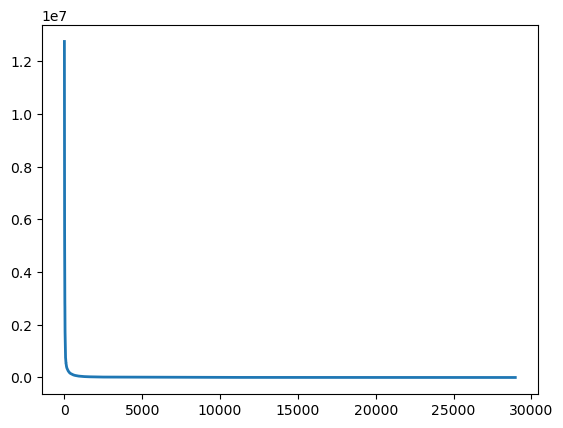

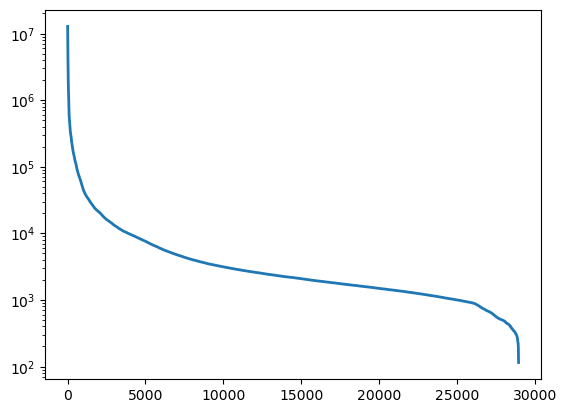

In [30]:
# Cumulative Length
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Length'], 
         label='Cumulative Length', linewidth=2, )
plt.show()
# plt.yscale("log")

# Cumulative Length
plt.plot(range(1, len(sorted_by_length) + 1), sorted_by_length['Length'], 
         label='Cumulative Length', linewidth=2, )
plt.yscale("log")
plt.show()

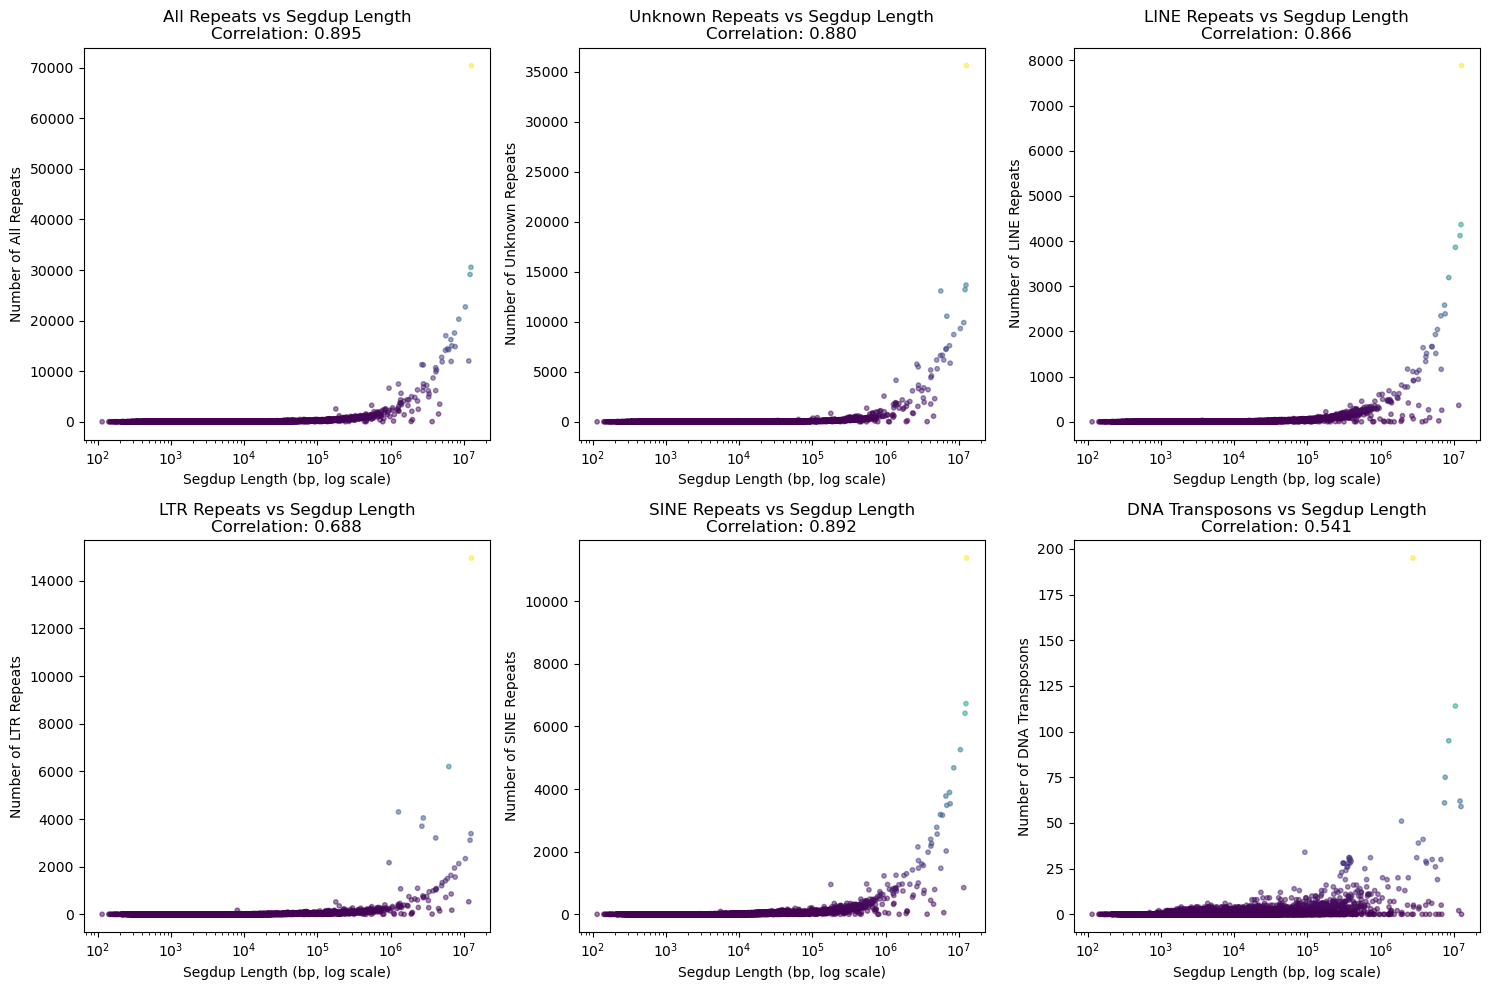

In [31]:
# `repeat_types` was used here but never defined anywhere in the notebook,
# which raised NameError. Defined explicitly: (count column, plot title).
repeat_types = [
    ("repeat_count", "All Repeats"),
    ("unknown_repeat_count", "Unknown Repeats"),
    ("LINE_repeat_count", "LINE Repeats"),
    ("LTR_repeat_count", "LTR Repeats"),
    ("SINE_repeat_count", "SINE Repeats"),
    ("DNA_transposon_repeat_count", "DNA Transposons"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for i, (col_name, title) in enumerate(repeat_types):
    if i < len(axes):
        axes[i].scatter(merged_segdup["Length"], merged_segdup[col_name],
                        alpha=0.5, s=10, c=merged_segdup[col_name], cmap="viridis")
        axes[i].set_xlabel("Segdup Length (bp)")
        axes[i].set_ylabel(f"Number of {title}")
        corr = merged_segdup["Length"].corr(merged_segdup[col_name])
        axes[i].set_title(f"{title} vs Segdup Length\nCorrelation: {corr:.3f}")

        if merged_segdup["Length"].max() / merged_segdup["Length"].min() > 100:
            axes[i].set_xscale("log")
            axes[i].set_xlabel("Segdup Length (bp, log scale)")

plt.tight_layout()
plt.show()


In [32]:
merged_segdup["gene_count"].value_counts()

gene_count
0     16459
1     11087
2      1204
3       120
4        38
5        22
6        11
7         7
9         3
8         2
13        2
12        2
15        1
17        1
10        1
11        1
Name: count, dtype: int64

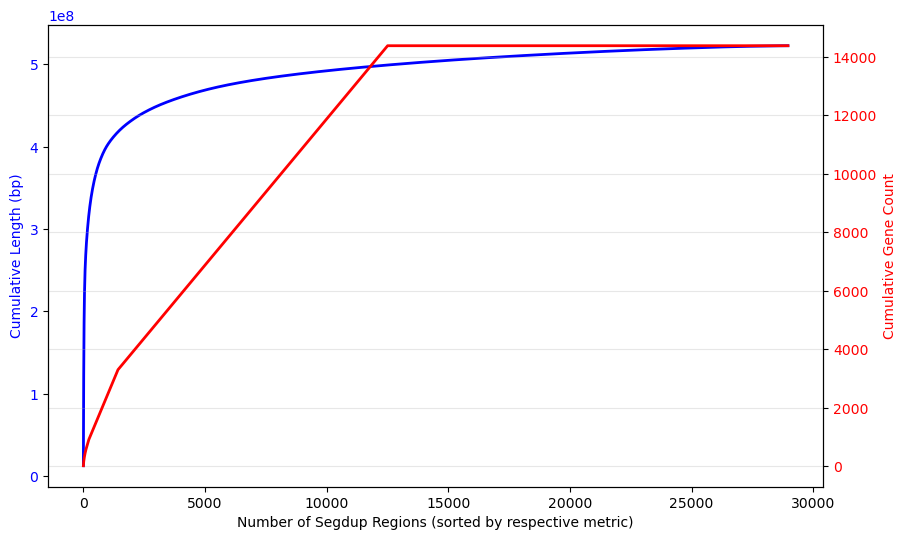

In [33]:
# Exploratory twin-axis view.
#
# This cell used to reassign `sorted_by_length` while computing only
# Cumulative_Length (not Cumulative_Length_Pct), which wiped that column and
# made a re-run of the segdup_hotspots cell fail with
# KeyError: 'Cumulative_Length_Pct'. It now uses private local names instead.

_sorted_len = merged_segdup.sort_values("Length", ascending=False).copy()
_sorted_len["Cumulative_Length"] = _sorted_len["Length"].cumsum()

_sorted_genes = merged_segdup.sort_values("gene_count", ascending=False).copy()
_sorted_genes["Cumulative_Genes"] = _sorted_genes["gene_count"].cumsum()

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(range(1, len(_sorted_len) + 1), _sorted_len["Cumulative_Length"],
         color="blue", label="Cumulative Length", linewidth=2)
ax1.set_xlabel("Number of Segdup Regions (sorted by respective metric)")
ax1.set_ylabel("Cumulative Length (bp)", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

ax2 = ax1.twinx()
ax2.plot(range(1, len(_sorted_genes) + 1), _sorted_genes["Cumulative_Genes"],
         color="red", label="Cumulative Gene Count", linewidth=2)
ax2.set_ylabel("Cumulative Gene Count", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.grid(True, alpha=0.3)
plt.show()
